# 03c - Bot, DDoS and Prob

`03b_strong_models.ipynb` showed that Bot, DDoS and Prob are the hard classes: the tuned models confuse Bot with DDoS and Prob with DDoS and Benign, and `balanced` and SMOTE only move errors from one class to another. This notebook collects the analyses of why, and closes the topic:

1. Evidence of the overlap (zero bytes, rows with the same features but different labels)
2. A model trained only on the three classes
3. New features computed from the existing columns
4. Threshold analysis for Bot (analysis only, the demo model is not changed)
5. Limitations and future work

Decisions are made with cross-validation on the training set. The test set is only used to report the result once, after the decision. Nothing here changes `results_strong.csv` or `best_model.joblib`.

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import f1_score, precision_recall_fscore_support

from src.config import RANDOM_STATE, FEATURE_COLS

train = pd.read_parquet('../data/processed/train.parquet')
test  = pd.read_parquet('../data/processed/test.parquet')

X_train, y_train = train[FEATURE_COLS], train['label_multi']
X_test,  y_test  = test[FEATURE_COLS],  test['label_multi']

HARD = ['Bot', 'DDoS', 'Prob']
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (341633, 62) | Test: (85409, 62)


In [2]:
def per_class(y_true, y_pred, labels):
    """Precision, recall and F1 per class as a DataFrame."""
    p, r, f, n = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support': n}, index=labels).round(3)

## 2. Evidence of the overlap

### Zero bytes
Share of training rows with `Flow Byts/s` = 0 per class (also shown in `03b`, section 7).

In [3]:
(train['Flow Byts/s'] == 0).groupby(y_train).mean().mul(100).round(1).rename('% zero bytes')

label_multi
Benign     47.8
Bot       100.0
DDoS      100.0
Dos        22.0
Prob      100.0
Name: % zero bytes, dtype: float64

In [4]:
varying = [c for c in FEATURE_COLS if X_train.loc[y_train.isin(HARD), c].nunique() > 1]
print(f'Features that vary within Bot/DDoS/Prob: {len(varying)} of {len(FEATURE_COLS)}')
print(varying)

Features that vary within Bot/DDoS/Prob: 30 of 62
['Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Down/Up Ratio', 'Subflow Fwd Pkts', 'Subflow Bwd Pkts', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']


### Rows with the same features but different labels
A row is *conflicting* if exactly the same 62 feature values also appear in the training set with another label. No model can classify both rows correctly. The share depends on which rows are counted, so three versions are shown. The rows are compared with a 64-bit hash of the feature values.

In [5]:
def conflicting(df):
    """True for rows whose feature vector appears in df with more than one label."""
    key = pd.util.hash_pandas_object(df[FEATURE_COLS], index=False)
    n_labels = df.groupby(key)['label_multi'].nunique()
    return key.map(n_labels).gt(1)

hard = y_train.isin(HARD)
conf_all = conflicting(train)
conf_hard = conflicting(train[hard])

pd.DataFrame({
    'rows counted': ['all train rows, all 5 classes',
                     'Bot/DDoS/Prob rows, compared only with each other',
                     'Bot/DDoS/Prob rows, compared with all classes'],
    'conflicting': [conf_all.sum(), conf_hard.sum(), conf_all[hard].sum()],
    'total': [len(train), hard.sum(), hard.sum()],
}).assign(percent=lambda d: (100 * d.conflicting / d.total).round(2))

,rows counted,conflicting,total,percent
0,"all train rows, all 5 classes",1146,341633,0.34
1,"Bot/DDoS/Prob rows, compared only with each other",253,53432,0.47
2,"Bot/DDoS/Prob rows, compared with all classes",555,53432,1.04


In [6]:
print('Conflicting rows per class (all train rows):')
print(y_train[conf_all].value_counts())

Conflicting rows per class (all train rows):


label_multi
Dos       324
Benign    267
DDoS      247
Bot       181
Prob      127
Name: count, dtype: int64


**Which number is which.** The share of conflicting rows is **0.34%** when all training rows are counted (1,146 of 341,633, all 5 classes). This is the "0.3%" in the team report (v2). Counting only the Bot, DDoS and Prob rows and comparing them only with each other gives **0.47%** (253 of 53,432). If they are compared with all classes, **1.04%** of them (555) have a copy with another label. All three numbers are small: the classes are not identical, so the overlap is not complete. The problem is that the rows are close, not that they are the same.

## 3. A model for the three classes only
If the problem were that Bot and Prob are lost among the many Benign, Dos and DDoS rows, a model that sees only Bot, DDoS and Prob should separate them better. LightGBM with default settings, cross-validated on the training rows of the three classes and then tested once on the test rows of the three classes.

In [7]:
hard_te = y_test.isin(HARD)
lgbm3 = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

cv3 = cross_val_score(lgbm3, X_train[hard], y_train[hard], cv=cv, scoring='f1_macro')
print(f'CV macro F1 (3 classes): {cv3.mean():.4f} ± {cv3.std():.4f}')

lgbm3.fit(X_train[hard], y_train[hard])
pred3 = lgbm3.predict(X_test[hard_te])
print(f'Test macro F1 (3 classes): {f1_score(y_test[hard_te], pred3, average="macro"):.4f}')
per_class(y_test[hard_te], pred3, HARD)

CV macro F1 (3 classes): 0.5783 ± 0.0065


Test macro F1 (3 classes): 0.5766


,precision,recall,f1,support
Bot,0.537,0.081,0.141,1792
DDoS,0.814,0.981,0.890,10054
Prob,0.895,0.574,0.700,1513


In [8]:
pd.crosstab(y_test[hard_te], pred3, rownames=['true'], colnames=['predicted'], normalize='index').round(3)

predicted,Bot,DDoS,Prob
true,,,
Bot,0.081,0.914,0.005
DDoS,0.010,0.981,0.009
Prob,0.017,0.408,0.574


**A separate model does not help.** Even when Benign and Dos are removed, 91% of the Bot test flows are predicted as DDoS and Bot recall is 0.08 (Bot F1 0.14). Prob recall is 0.57 and 41% of Prob goes to DDoS. So Bot is not lost because of the other classes: with the features we have, Bot and DDoS look the same to the model.

## 4. New features from the existing columns
Trees split on one column at a time, so they cannot easily use the ratio of two columns. We add 10 ratios that describe how regular the timing is and how the packets are split between the two directions. Bot flows, for example, could be more regular (small std compared to the mean). `+1` in the denominator avoids division by zero. All 10 can be computed from a single flow, so the demo could compute them too.

| Feature | Meaning |
|---|---|
| `flow_iat_cv`, `fwd_iat_cv` | std / mean of the time between packets (flow, forward) |
| `idle_cv`, `active_cv` | std / mean of idle and active times |
| `iat_min_max` | shortest / longest time between packets |
| `active_idle` | active mean / idle mean |
| `tot_pkts` | forward + backward packets |
| `bwd_fwd_pkts` | backward / forward packets |
| `dur_per_pkt` | flow duration / total packets |
| `bwd_fwd_iat` | backward / forward mean time between packets |

**Decision rule, fixed before the run:** the features are kept only if the 3-fold CV macro F1 of LightGBM (default settings, 5 classes) goes up by more than the fold-to-fold standard deviation.

In [9]:
def ratio(a, b):
    return a / (b + 1)

def add_ratio_features(df):
    out = df.copy()
    out['flow_iat_cv']  = ratio(df['Flow IAT Std'], df['Flow IAT Mean'])
    out['fwd_iat_cv']   = ratio(df['Fwd IAT Std'], df['Fwd IAT Mean'])
    out['idle_cv']      = ratio(df['Idle Std'], df['Idle Mean'])
    out['active_cv']    = ratio(df['Active Std'], df['Active Mean'])
    out['iat_min_max']  = ratio(df['Flow IAT Min'], df['Flow IAT Max'])
    out['active_idle']  = ratio(df['Active Mean'], df['Idle Mean'])
    out['tot_pkts']     = df['Tot Fwd Pkts'] + df['Tot Bwd Pkts']
    out['bwd_fwd_pkts'] = ratio(df['Tot Bwd Pkts'], df['Tot Fwd Pkts'])
    out['dur_per_pkt']  = ratio(df['Flow Duration'], df['Tot Fwd Pkts'] + df['Tot Bwd Pkts'])
    out['bwd_fwd_iat']  = ratio(df['Bwd IAT Mean'], df['Fwd IAT Mean'])
    return out

NEW_COLS = ['flow_iat_cv', 'fwd_iat_cv', 'idle_cv', 'active_cv', 'iat_min_max',
            'active_idle', 'tot_pkts', 'bwd_fwd_pkts', 'dur_per_pkt', 'bwd_fwd_iat']
X_train_fe = add_ratio_features(X_train)
X_test_fe  = add_ratio_features(X_test)
print('Columns with new features:', X_train_fe.shape[1])

Columns with new features: 72


In [10]:
fe_rows, fe_models = [], {}
for name, cols in [('62 features', FEATURE_COLS), ('62 + 10 new', FEATURE_COLS + NEW_COLS)]:
    model = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    scores = cross_val_score(model, X_train_fe[cols], y_train, cv=cv, scoring='f1_macro')
    model.fit(X_train_fe[cols], y_train)
    pred = model.predict(X_test_fe[cols])
    f1s = dict(zip(model.classes_, f1_score(y_test, pred, labels=model.classes_, average=None)))
    fe_models[name] = model
    fe_rows.append({'features': name, 'cv_mean': scores.mean(), 'cv_std': scores.std(),
                    'test_macro_f1': f1_score(y_test, pred, average='macro'),
                    **{f'{c} F1': f1s[c] for c in HARD}})
fe_table = pd.DataFrame(fe_rows).round(4)
fe_table

,features,cv_mean,cv_std,test_macro_f1,Bot F1,DDoS F1,Prob F1
0,62 features,0.6524,0.0018,0.6470,0.0981,0.6788,0.5906
1,62 + 10 new,0.6526,0.0017,0.6452,0.0967,0.6786,0.5838


In [11]:
gain = fe_table.cv_mean.iloc[1] - fe_table.cv_mean.iloc[0]
print(f'CV gain: {gain:+.4f}, fold std: {fe_table.cv_std.max():.4f}, keep new features: {gain > fe_table.cv_std.max()}')

m = fe_models['62 + 10 new']
imp = pd.Series(m.booster_.feature_importance('gain'), index=FEATURE_COLS + NEW_COLS)
rank = imp.rank(ascending=False).astype(int)
pd.DataFrame({'gain': imp[NEW_COLS].round(0), 'rank (of 72)': rank[NEW_COLS]}).sort_values('rank (of 72)')

CV gain: +0.0002, fold std: 0.0018, keep new features: False


,gain,rank (of 72)
bwd_fwd_pkts,290595.0,3
fwd_iat_cv,38730.0,16
flow_iat_cv,26590.0,19
iat_min_max,18630.0,22
dur_per_pkt,5313.0,35
bwd_fwd_iat,2815.0,46
tot_pkts,2318.0,49
idle_cv,1549.0,51
active_idle,982.0,54
active_cv,440.0,61


**The new features are not kept.** The CV gain is +0.0002, far below the fold standard deviation (0.0018), and the test F1 of Bot, DDoS and Prob does not change. The model does use some of the new features (`bwd_fwd_pkts` is the 3rd most important of 72), but it uses them instead of the old ones, not in addition. Ratios of the existing columns do not add information that the model did not already have.

## 5. Threshold analysis for Bot

**This is an analysis, not a change of the demo model.** The model for the demo and the Mininet test is not final yet, and `best_model.joblib` is not changed here. We use the tuned LightGBM from `03b` (section 6), because it is fast enough for cross-validated probabilities. The same method works for the tuned Random Forest.

A classifier predicts the class with the highest probability. If we multiply the Bot probability by a weight `w` before taking the highest, `w > 1` makes the model predict Bot more often: Bot recall goes up, Bot precision goes down, and the rows come mostly from DDoS. This is the same trade-off as `balanced`, but chosen after training and easy to change.

**Selection criterion, fixed before looking at any result:**
- The probabilities come from 3-fold `cross_val_predict` on the training set (out-of-fold: each row is predicted by a model that did not see it).
- `w` is tried on a grid from 0.25 to 10.
- The chosen `w` is the one with the **highest out-of-fold macro F1**. If several are within 0.001 of the best, the one closest to 1 (the smallest change) is chosen.
- The test set is used once, after `w` is fixed, to compare `w = 1` and the chosen `w`.
- Bot precision, Bot recall and **DDoS recall** are shown next to macro F1, because DDoS is the class that pays for a higher Bot recall.

In [12]:
LGBM_TUNED = dict(subsample=0.6, num_leaves=63, n_estimators=500, min_child_samples=50,
                  max_depth=10, learning_rate=0.1, colsample_bytree=0.8, subsample_freq=1)

lgbm_t = LGBMClassifier(**LGBM_TUNED, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
oof_proba = cross_val_predict(lgbm_t, X_train, y_train, cv=cv, method='predict_proba')
CLASSES = np.sort(y_train.unique())   # column order of cross_val_predict
BOT = list(CLASSES).index('Bot')
print('Classes:', list(CLASSES), '| OOF shape:', oof_proba.shape)

Classes: ['Benign', 'Bot', 'DDoS', 'Dos', 'Prob'] | OOF shape: (341633, 5)


In [13]:
def predict_weighted(proba, w):
    p = proba.copy()
    p[:, BOT] *= w
    return CLASSES[p.argmax(axis=1)]

def threshold_row(y_true, proba, w):
    pred = predict_weighted(proba, w)
    pc = per_class(y_true, pred, list(CLASSES))
    return {'w': w, 'macro_f1': f1_score(y_true, pred, average='macro'),
            'bot_precision': pc.loc['Bot', 'precision'], 'bot_recall': pc.loc['Bot', 'recall'],
            'ddos_recall': pc.loc['DDoS', 'recall'], 'prob_recall': pc.loc['Prob', 'recall']}

W_GRID = np.round(np.concatenate([np.arange(0.25, 1, 0.25), np.arange(1, 3.01, 0.25),
                                  np.arange(3.5, 10.01, 0.5)]), 2)
oof_table = pd.DataFrame([threshold_row(y_train, oof_proba, w) for w in W_GRID])

best = oof_table.macro_f1.max()
near = oof_table[oof_table.macro_f1 >= best - 0.001]
w_star = near.loc[(near.w - 1).abs().idxmin(), 'w']
print(f'Best OOF macro F1: {best:.4f} | within 0.001: {list(near.w)} | chosen w: {w_star}')
oof_table.round(3)

Best OOF macro F1: 0.6906 | within 0.001: [2.0, 2.25, 2.5, 2.75] | chosen w: 2.0


,w,macro_f1,bot_precision,bot_recall,ddos_recall,prob_recall
0,0.25,0.636,0.577,0.019,0.806,0.527
1,0.50,0.646,0.511,0.045,0.803,0.526
2,0.75,0.656,0.433,0.079,0.799,0.526
3,1.00,0.665,0.385,0.118,0.791,0.526
4,1.25,0.673,0.349,0.165,0.779,0.526
5,1.50,0.682,0.322,0.236,0.759,0.525
6,1.75,0.687,0.306,0.295,0.742,0.525
7,2.00,0.690,0.294,0.354,0.725,0.525
8,2.25,0.691,0.277,0.410,0.701,0.525
9,2.50,0.691,0.268,0.461,0.679,0.524


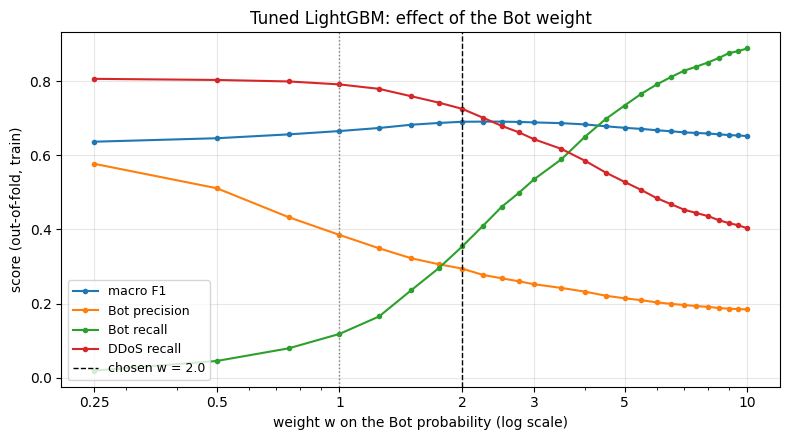

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, label in [('macro_f1', 'macro F1'), ('bot_precision', 'Bot precision'),
                   ('bot_recall', 'Bot recall'), ('ddos_recall', 'DDoS recall')]:
    ax.plot(oof_table.w, oof_table[col], marker='o', ms=3, label=label)
ax.axvline(1, color='grey', ls=':', lw=1)
ax.axvline(w_star, color='black', ls='--', lw=1, label=f'chosen w = {w_star}')
ax.set_xscale('log')
ax.set_xticks([0.25, 0.5, 1, 2, 3, 5, 10])
ax.set_xticklabels(['0.25', '0.5', '1', '2', '3', '5', '10'])
ax.set_xlabel('weight w on the Bot probability (log scale)')
ax.set_ylabel('score (out-of-fold, train)')
ax.set_title('Tuned LightGBM: effect of the Bot weight')
ax.legend(loc='lower left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The weight is now fixed. The model is trained on the full training set and the test set is used once.

In [15]:
lgbm_t.fit(X_train, y_train)
test_proba = lgbm_t.predict_proba(X_test)
assert list(lgbm_t.classes_) == list(CLASSES)
pd.DataFrame([threshold_row(y_test, test_proba, w) for w in sorted({1.0, w_star})]).round(4)

,w,macro_f1,bot_precision,bot_recall,ddos_recall,prob_recall
0,1.0,0.6599,0.397,0.110,0.806,0.486
1,2.0,0.6884,0.308,0.352,0.742,0.485


**Result of the analysis.** The criterion chose `w = 2` (out-of-fold macro F1 0.691; 2.25 to 2.75 are within 0.001 and further from 1). On the test set:

- Macro F1 goes from 0.660 to **0.688**. This is higher than the tuned Random Forest in `03b` (0.673).
- Bot recall goes from 0.11 to 0.35, Bot precision from 0.40 to 0.31: about 7 of 10 flows predicted as Bot are not Bot.
- **DDoS recall drops from 0.81 to 0.74.** Prob is not affected (0.49).

LightGBM with several threads gives slightly different numbers from run to run (in the third decimal), so the values here are rounded.

The gain in macro F1 comes from Bot F1 rising more than DDoS F1 falls. Whether this is better depends on the cost of a missed Bot compared with a missed DDoS, which macro F1 does not know. **This is an analysis only.** The demo model is not decided and nothing is saved. If the team chooses LightGBM, the weight is one line after `predict_proba`. For the Random Forest the same out-of-fold analysis would have to be repeated, because its probabilities are on a different scale.

## 6. Limitations and future work

### What the data allows
| Evidence | Result |
|---|---|
| Byte features of Bot, DDoS and Prob | 0 in 100% of the rows (Benign 48%, Dos 22%) |
| `Protocol` and ports (EDA) | 0 for all Bot, DDoS and Prob flows: the packet headers were probably not read |
| Features that still vary in the three classes | 30 of 62, all timing or packet counts |
| Same features, different label | 0.34% of all rows, 1.04% of Bot/DDoS/Prob rows |
| Model for the three classes only | Bot recall 0.08, 91% of Bot predicted as DDoS |
| 10 ratio features | CV +0.0002 (std 0.0018), not kept |
| `balanced`, SMOTE, scaled SMOTE (`03b`) | move errors between Bot and DDoS, macro F1 lower |
| Bot weight `w = 2` | macro F1 0.660 → 0.688, but Bot precision 0.31 and DDoS recall 0.81 → 0.74 |

Each flow in the processed data is described only by its own timing and packet counts, and for Bot, DDoS and Prob these are very similar. The limit is in the information each row carries, not in the choice of model or balancing method.

### Future work: features across flows
Bot, DDoS and Prob differ mainly in how many flows there are and between which hosts, which a single row cannot show:
- **DDoS:** many sources send to one target in a short time.
- **Prob (scan):** one source contacts many targets or ports.
- **Bot:** one host contacts the same server at regular intervals.

The raw data has `Src IP`, `Dst IP` and `Timestamp`, which are removed in preprocessing. Counts over a time window could describe this, for example the number of different sources that sent to the same target in the last N seconds. This was **not done** in this project, because it changes the shared preprocessing, and it has risks that must be handled first:
- **Leakage through addresses:** in a lab dataset the attackers use a few fixed IPs. A model that sees the IP, or a feature that identifies it, learns the address, not the behaviour, and fails on another network. Only counts can be used, never the addresses.
- **Leakage through time:** a random train/test split puts flows from the same attack, seconds apart, in both sets, and window counts then contain information from the test flows. A split by time (train on earlier, test on later) is needed.
- **Window counts are computed from the past only**, and the same features must be computed live in the controller for the demo and Mininet, with the same window size.

## 7. Summary

- Bot, DDoS and Prob have zero bytes in all flows, so only timing and packet counts are left, and these overlap. Only 0.34% of all rows (1.04% of the three classes) are exact copies with another label: the classes are close, not identical.
- A model trained only on the three classes still predicts 91% of Bot as DDoS (Bot recall 0.08), and 10 ratio features do not change the CV score (+0.0002). Better modelling of the same columns does not separate the classes.
- A weight of 2 on the Bot probability of the tuned LightGBM, chosen on out-of-fold predictions, raises test macro F1 from 0.660 to 0.688, at the cost of Bot precision 0.31 and DDoS recall 0.74. This is an analysis; the demo model is not changed.
- Features across flows (counts per source and target over time) are the likely next step, with a time-based split and without the addresses themselves, to avoid leakage. They are left as future work.